# Outlier detection with a diffusion model and empirical p-values

A diffusion model is trained on one class of Fashion-MNIST (pullovers).
Images from the other classes are outliers.
The anomaly score of an image is its reconstruction error after partial noising.
The score is turned into a p-value, which controls the false alarm rate.

Run the cells in order, with a GPU (Runtime > Change runtime type > GPU).

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets
from sklearn.metrics import roc_auc_score
from scipy.stats import norm
import os

os.makedirs("figures", exist_ok=True)   # folder for the saved figures

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 1. Data

The official train and test sets are merged: 7,000 images per class.
The normal class is split into 4,000 training images and 3,000 held-out images.
The held-out images are never seen by the model.

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.8MB/s]


Normal class: Pullover
Train: 4000 | Holdout: 3000 | Outliers: 3000


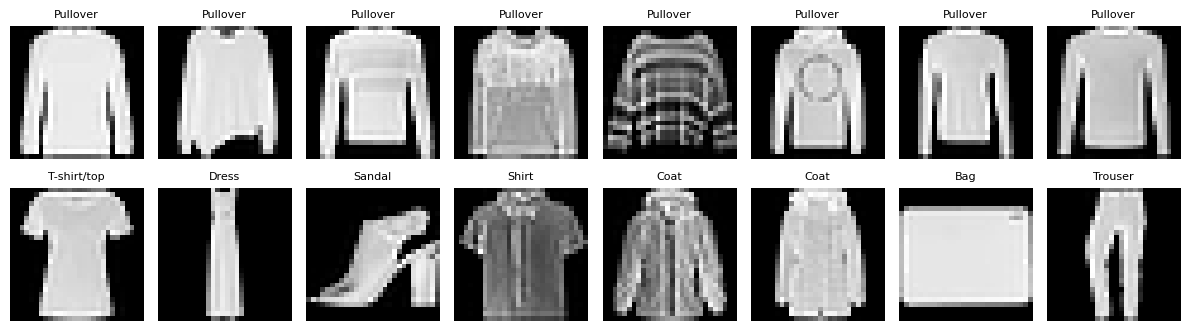

In [2]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Load Fashion-MNIST and merge the official train and test sets (70,000 images)
train = datasets.FashionMNIST("data", train=True, download=True)
test = datasets.FashionMNIST("data", train=False, download=True)

images = torch.cat([train.data, test.data]).float() / 255   # pixels in [0, 1]
images = 2 * images - 1                                      # pixels in [-1, 1], as in DDPM
images = images.unsqueeze(1)                                 # shape (70000, 1, 28, 28)
labels = torch.cat([train.targets, test.targets]).numpy()

# The normal class; images from the 9 other classes are outliers
normal_class = 2   # Pullover
rng = np.random.default_rng(0)

# Normal images: 4000 to train the model, the rest (3000) kept aside
normal_idx = rng.permutation(np.where(labels == normal_class)[0])
train_idx = normal_idx[:4000]
holdout_idx = normal_idx[4000:]

# Outliers: a random subset of 3000 images from the other classes
other_idx = np.where(labels != normal_class)[0]
outlier_idx = rng.choice(other_idx, size=3000, replace=False)

print("Normal class:", class_names[normal_class])
print("Train:", len(train_idx), "| Holdout:", len(holdout_idx), "| Outliers:", len(outlier_idx))

# Show 8 normal images (top row) and 8 outliers (bottom row)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axes[0, i].imshow(images[train_idx[i], 0], cmap="gray")
    axes[0, i].set_title(class_names[labels[train_idx[i]]], fontsize=8)
    axes[1, i].imshow(images[outlier_idx[i], 0], cmap="gray")
    axes[1, i].set_title(class_names[labels[outlier_idx[i]]], fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

## 2. Model

A small U-Net predicts the noise added to an image at time step t.
The time step is encoded by a learned vector added in each block.

In [3]:
class Block(nn.Module):
    """Two 3x3 convolutions. The time step information is added in between,
    so the network knows how much noise the image contains."""

    def __init__(self, c_in, c_out, t_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, c_out)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.time = nn.Linear(t_dim, c_out)

    def forward(self, x, t_emb):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.time(t_emb)[:, :, None, None]   # same value added to every pixel
        h = F.silu(self.norm2(self.conv2(h)))
        return h


class UNet(nn.Module):
    """Small U-Net that predicts the noise added to a 28x28 image at time step t.

    Encoder: 28x28 -> 14x14 -> 7x7, decoder: 7x7 -> 14x14 -> 28x28.
    Skip connections pass encoder features directly to the decoder.
    """

    def __init__(self, T=1000, t_dim=128):
        super().__init__()
        self.time_emb = nn.Embedding(T, t_dim)       # one learned vector per time step

        self.down1 = Block(1, 32, t_dim)             # 28x28
        self.down2 = Block(32, 64, t_dim)            # 14x14
        self.mid = Block(64, 128, t_dim)             # 7x7
        self.up2 = Block(128 + 64, 64, t_dim)        # 14x14
        self.up1 = Block(64 + 32, 32, t_dim)         # 28x28
        self.out = nn.Conv2d(32, 1, 1)

        self.pool = nn.MaxPool2d(2)                  # halves the image size
        self.upsample = nn.Upsample(scale_factor=2)  # doubles the image size

    def forward(self, x, t):
        t_emb = self.time_emb(t)

        h1 = self.down1(x, t_emb)
        h2 = self.down2(self.pool(h1), t_emb)
        h3 = self.mid(self.pool(h2), t_emb)

        h = self.up2(torch.cat([self.upsample(h3), h2], dim=1), t_emb)
        h = self.up1(torch.cat([self.upsample(h), h1], dim=1), t_emb)
        return self.out(h)

## 3. Training

The model is a DDPM with T = 1000 steps and a linear noise schedule.
It learns to recover the noise added to the training pullovers.
Images generated from pure noise check that the model has learned what a pullover is.

Epoch 0, loss 0.4963
Epoch 10, loss 0.0842
Epoch 20, loss 0.0662
Epoch 30, loss 0.0605
Epoch 40, loss 0.0578
Epoch 50, loss 0.0587
Epoch 60, loss 0.0521
Epoch 70, loss 0.0486
Epoch 80, loss 0.0497
Epoch 90, loss 0.0510
Epoch 100, loss 0.0484
Epoch 110, loss 0.0485
Epoch 120, loss 0.0476
Epoch 130, loss 0.0462
Epoch 140, loss 0.0472
Epoch 150, loss 0.0455
Epoch 160, loss 0.0439
Epoch 170, loss 0.0444
Epoch 180, loss 0.0418
Epoch 190, loss 0.0432
Epoch 200, loss 0.0448
Epoch 210, loss 0.0446
Epoch 220, loss 0.0443
Epoch 230, loss 0.0398
Epoch 240, loss 0.0434
Epoch 250, loss 0.0398
Epoch 260, loss 0.0412
Epoch 270, loss 0.0436
Epoch 280, loss 0.0418
Epoch 290, loss 0.0424


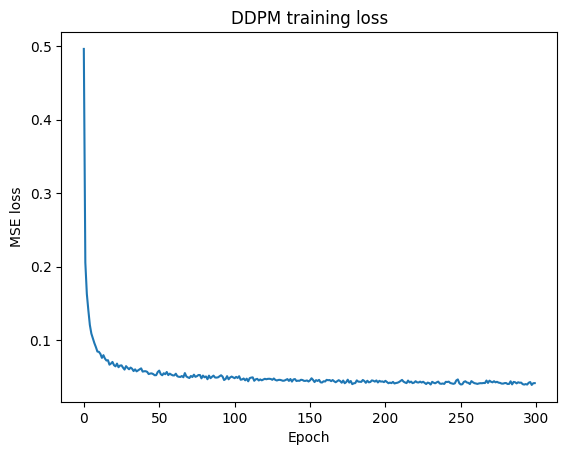

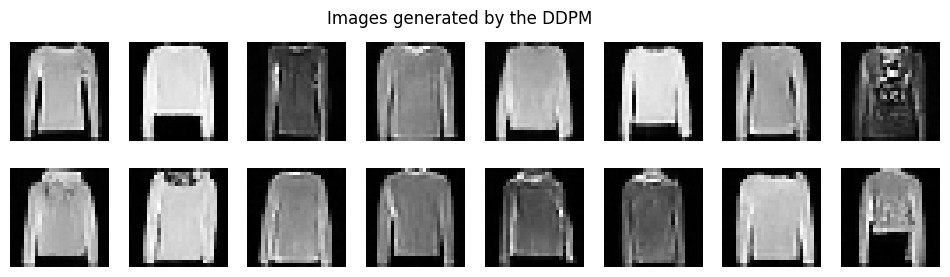

In [4]:
x_train = images[train_idx]

# Noise schedule: beta_t grows linearly, alpha_bar_t = prod_{s<=t} (1 - beta_s)
T = 1000
betas = torch.linspace(1e-4, 0.02, T).to(device)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

model = UNet(T).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)

n_epochs = 300
batch_size = 128
losses = []

for epoch in range(n_epochs):
    perm = torch.randperm(len(x_train))
    epoch_loss = 0

    for i in range(0, len(x_train), batch_size):
        x0 = x_train[perm[i:i + batch_size]].to(device)

        # Noisy image at a random time step: x_t = sqrt(alpha_bar_t) x_0 + sqrt(1 - alpha_bar_t) eps
        t = torch.randint(0, T, (len(x0),), device=device)
        eps = torch.randn_like(x0)
        a = alpha_bars[t].view(-1, 1, 1, 1)
        xt = torch.sqrt(a) * x0 + torch.sqrt(1 - a) * eps

        # The network learns to recover the noise eps from x_t
        loss = ((model(xt, t) - eps) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(x0)

    losses.append(epoch_loss / len(x_train))
    if epoch % 10 == 0:
        print(f"Epoch {epoch}, loss {losses[-1]:.4f}")

torch.save(model.state_dict(), "ddpm_pullover.pt")

# Training loss
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("DDPM training loss")
plt.savefig("figures/training_loss.png", dpi=150)
plt.show()

# Visual check: generate 16 images starting from pure noise (DDPM sampling)
model.eval()
with torch.no_grad():
    x = torch.randn(16, 1, 28, 28, device=device)
    for t in reversed(range(T)):
        t_batch = torch.full((16,), t, device=device)
        eps_hat = model(x, t_batch)
        # Mean of p(x_{t-1} | x_t), then add Gaussian noise except at the last step
        x = (x - betas[t] / torch.sqrt(1 - alpha_bars[t]) * eps_hat) / torch.sqrt(alphas[t])
        if t > 0:
            x = x + torch.sqrt(betas[t]) * torch.randn_like(x)
    x = x.clamp(-1, 1)   # keep pixels in the image range for display

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(16):
    axes[i // 8, i % 8].imshow(x[i, 0].cpu(), cmap="gray")
    axes[i // 8, i % 8].axis("off")
plt.suptitle("Images generated by the DDPM")
plt.savefig("figures/generated_samples.png", dpi=150)
plt.show()

## 4. Anomaly score

An image is noised up to step t, then denoised with DDIM in 20 steps.
The model only knows pullovers, so it rebuilds a pullover.
A normal image is rebuilt faithfully. An outlier is not.
The anomaly score is the squared error between the image and its reconstruction.

In [5]:
def reconstruct(x0, t_start, n_steps=20):
    """Noise the images up to step t_start, then denoise them with DDIM.

    The noise destroys part of the image. A model trained only on pullovers
    rebuilds a pullover, so an outlier is badly reconstructed.
    """
    # 1) Random noising: x_t = sqrt(alpha_bar_t) x_0 + sqrt(1 - alpha_bar_t) eps
    a = alpha_bars[t_start]
    x_noisy = torch.sqrt(a) * x0 + torch.sqrt(1 - a) * torch.randn_like(x0)

    # 2) Deterministic DDIM denoising from t_start to 0 in n_steps steps
    times = torch.linspace(t_start, 0, n_steps + 1).long()
    x = x_noisy
    for i in range(n_steps):
        t, t_next = times[i], times[i + 1]
        t_batch = torch.full((len(x),), t.item(), device=device)
        eps_hat = model(x, t_batch)

        # Estimate of the clean image, then move to the less noisy step t_next
        a_t, a_next = alpha_bars[t], alpha_bars[t_next]
        x0_hat = (x - torch.sqrt(1 - a_t) * eps_hat) / torch.sqrt(a_t)
        x0_hat = x0_hat.clamp(-1, 1)
        x = torch.sqrt(a_next) * x0_hat + torch.sqrt(1 - a_next) * eps_hat

    return x_noisy, x


def anomaly_scores(x, t_start, n_repeats=1, pool=1, batch_size=500):
    """Anomaly score of each image: squared error between the image and its
    reconstruction. A large score means a likely outlier.

    n_repeats : the error is averaged over several random noisings,
                which reduces the variance of the score
    pool      : the difference image is averaged over pool x pool squares
                before squaring, so the score reacts to differences in shape
                more than to fine details (pool = 1 gives the pixel-wise error)
    """
    scores = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            x0 = x[i:i + batch_size].to(device)
            error = torch.zeros(len(x0), device=device)
            for r in range(n_repeats):
                _, x_rec = reconstruct(x0, t_start)
                diff = F.avg_pool2d(x0 - x_rec, pool)   # local mean of the difference
                error += (diff ** 2).mean(dim=(1, 2, 3))
            scores.append((error / n_repeats).cpu().numpy())
    return np.concatenate(scores)


model.eval()

UNet(
  (time_emb): Embedding(1000, 128)
  (down1): Block(
    (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 32, eps=1e-05, affine=True)
    (norm2): GroupNorm(8, 32, eps=1e-05, affine=True)
    (time): Linear(in_features=128, out_features=32, bias=True)
  )
  (down2): Block(
    (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
    (time): Linear(in_features=128, out_features=64, bias=True)
  )
  (mid): Block(
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 128, eps=1e-05, affine=True)
    (norm2): GroupNorm(8

### Choice of the noise level t

Too little noise: the outlier survives and is rebuilt as it is.
Too much noise: even pullovers are badly rebuilt.
The level t is chosen on a validation set of 500 normal images and 500 outliers.
These images are not used afterwards.

t = 250: AUROC = 0.780
t = 400: AUROC = 0.827
t = 550: AUROC = 0.822
t = 700: AUROC = 0.776
t = 850: AUROC = 0.766


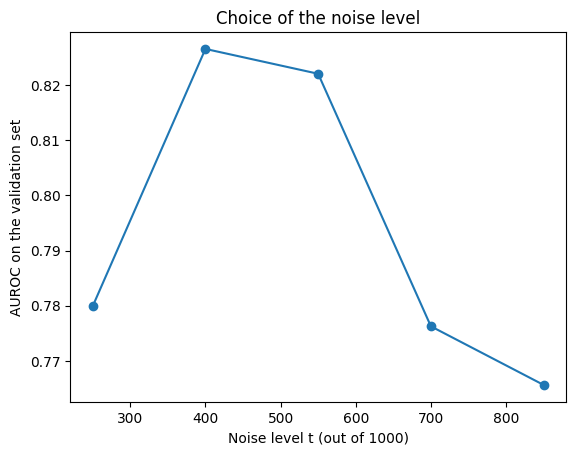

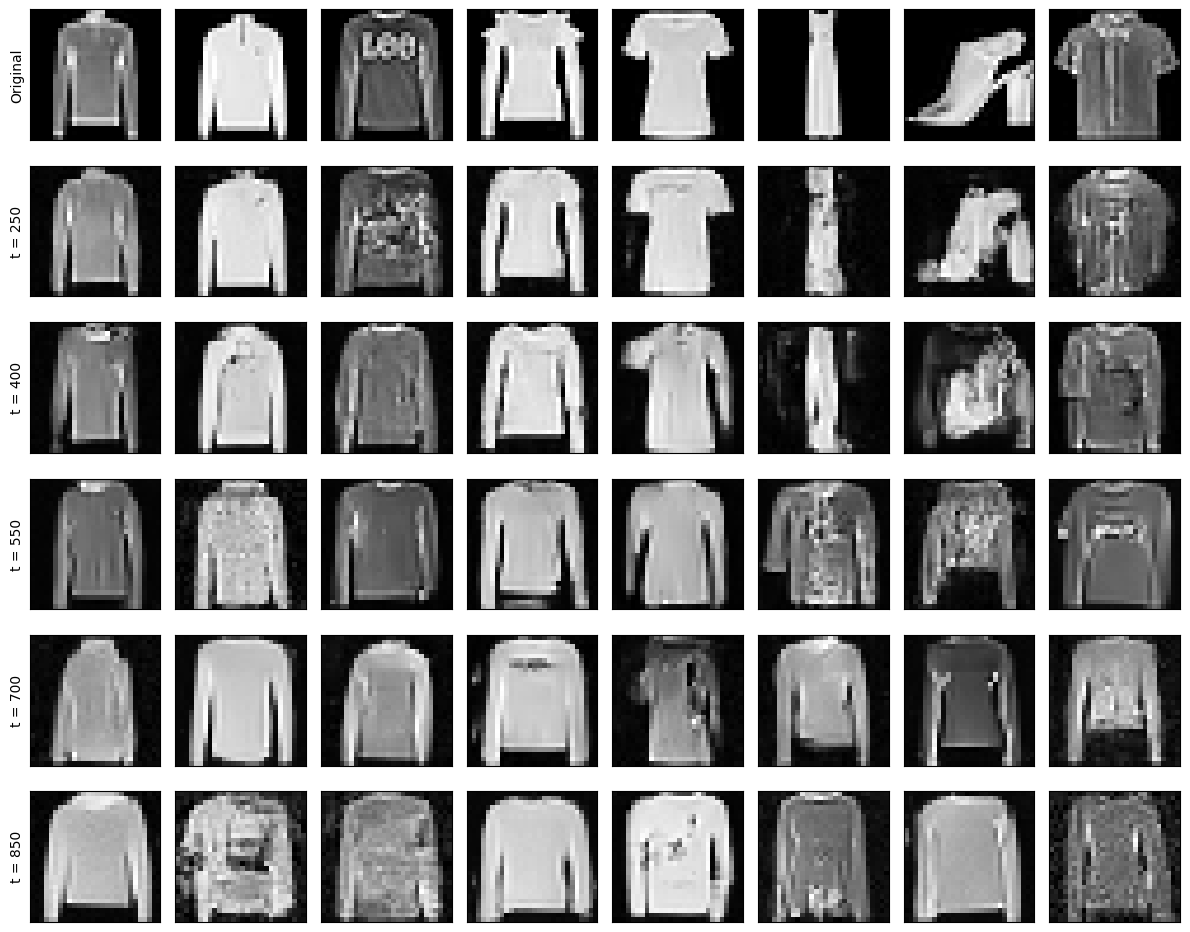

In [6]:
# Validation set used only to choose the score settings
val_normal = images[holdout_idx[:500]]
val_outlier = images[outlier_idx[:500]]
y_val = np.concatenate([np.zeros(500), np.ones(500)])

t_values = [250, 400, 550, 700, 850]
aurocs = []
torch.manual_seed(0)
for t in t_values:
    s = np.concatenate([anomaly_scores(val_normal, t), anomaly_scores(val_outlier, t)])
    aurocs.append(roc_auc_score(y_val, s))
    print(f"t = {t}: AUROC = {aurocs[-1]:.3f}")

plt.plot(t_values, aurocs, marker="o")
plt.xlabel("Noise level t (out of 1000)")
plt.ylabel("AUROC on the validation set")
plt.title("Choice of the noise level")
plt.savefig("figures/choice_of_t.png", dpi=150)
plt.show()

# Reconstructions of the same 8 images for each noise level
x0 = torch.cat([images[holdout_idx[:4]], images[outlier_idx[:4]]]).to(device)
fig, axes = plt.subplots(len(t_values) + 1, 8, figsize=(12, 1.6 * (len(t_values) + 1)))
for c in range(8):
    axes[0, c].imshow(x0[c, 0].cpu(), cmap="gray")
axes[0, 0].set_ylabel("Original")
with torch.no_grad():
    for r, t in enumerate(t_values):
        _, x_rec = reconstruct(x0, t)
        for c in range(8):
            axes[r + 1, c].imshow(x_rec[c, 0].cpu(), cmap="gray")
        axes[r + 1, 0].set_ylabel(f"t = {t}")
for ax in axes.flatten():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.savefig("figures/reconstructions_by_t.png", dpi=150)
plt.show()

### Improving the score

Two changes are tested on the same validation set.
Averaging over 5 noisings reduces the variance of the score.
Comparing images at 7x7 resolution reduces the weight of fine details.

In [7]:
variants = [(1, 1), (5, 1), (1, 4), (5, 4)]   # (n_repeats, pool)
torch.manual_seed(0)
for n_rep, p in variants:
    s_normal_val = anomaly_scores(val_normal, 550, n_rep, p)
    s_outlier_val = anomaly_scores(val_outlier, 550, n_rep, p)
    auroc = roc_auc_score(y_val, np.concatenate([s_normal_val, s_outlier_val]))
    detected = np.mean(s_outlier_val > np.quantile(s_normal_val, 0.95))
    print(f"n_repeats = {n_rep}, pool = {p}: AUROC = {auroc:.3f},"
          f" outliers detected at 5% = {detected:.2f}")

n_repeats = 1, pool = 1: AUROC = 0.830, outliers detected at 5% = 0.45
n_repeats = 5, pool = 1: AUROC = 0.862, outliers detected at 5% = 0.61
n_repeats = 1, pool = 4: AUROC = 0.845, outliers detected at 5% = 0.49
n_repeats = 5, pool = 4: AUROC = 0.894, outliers detected at 5% = 0.68


### Final scores

The chosen settings are t = 550, 5 noisings and a 7x7 comparison.
The scores are saved, so the statistical part does not need the network.

AUROC: 0.89


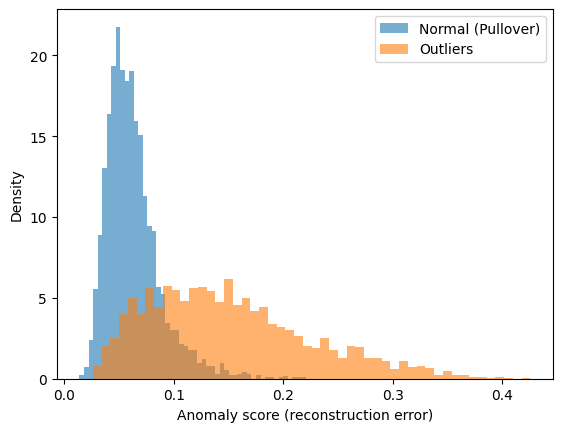

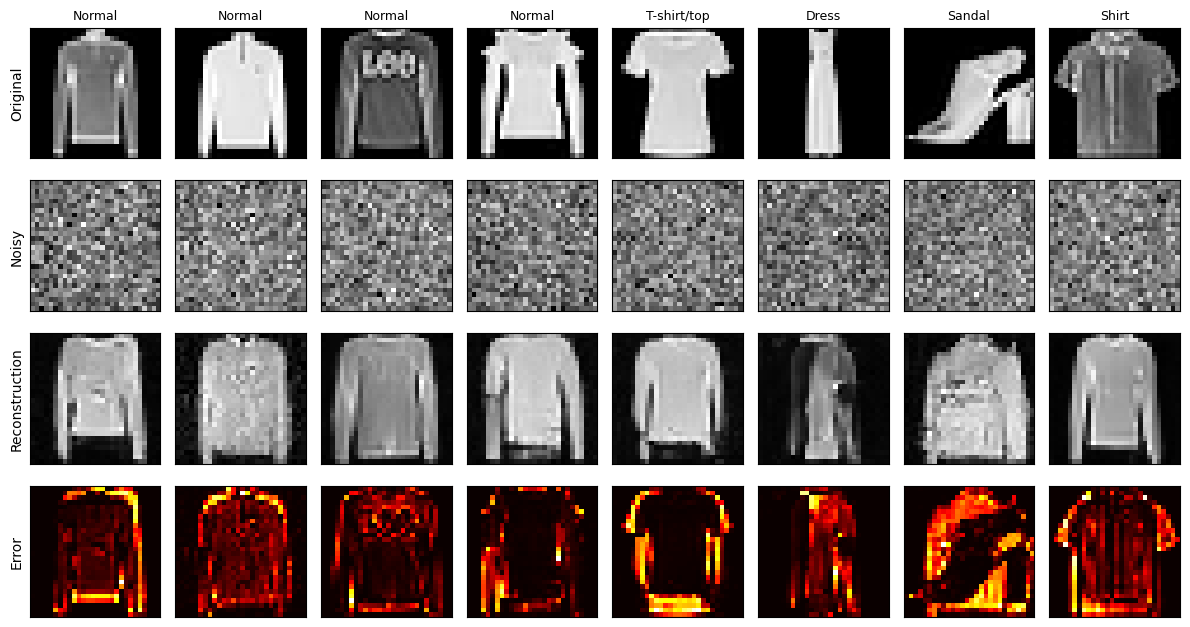

In [8]:
torch.manual_seed(0)
t_start = 550    # noise level out of T = 1000 steps
n_repeats = 5    # number of random noisings averaged
pool = 4         # images compared at 7x7 resolution

# Scores of the normal images kept aside and of the outliers
scores_normal = anomaly_scores(images[holdout_idx], t_start, n_repeats, pool)
scores_outlier = anomaly_scores(images[outlier_idx], t_start, n_repeats, pool)
np.save("scores_normal.npy", scores_normal)
np.save("scores_outlier.npy", scores_outlier)

# AUROC: probability that a random outlier gets a higher score than a random normal image
y = np.concatenate([np.zeros(len(scores_normal)), np.ones(len(scores_outlier))])
s = np.concatenate([scores_normal, scores_outlier])
print("AUROC:", round(roc_auc_score(y, s), 3))

# Distribution of the scores
plt.hist(scores_normal, bins=50, alpha=0.6, density=True, label="Normal (Pullover)")
plt.hist(scores_outlier, bins=50, alpha=0.6, density=True, label="Outliers")
plt.xlabel("Anomaly score (reconstruction error)")
plt.ylabel("Density")
plt.legend()
plt.savefig("figures/score_histogram.png", dpi=150)
plt.show()

# Original, noisy and reconstructed images, with the pixel-wise error map
x0 = torch.cat([images[holdout_idx[:4]], images[outlier_idx[:4]]]).to(device)
with torch.no_grad():
    x_noisy, x_rec = reconstruct(x0, t_start)
error_map = (x0 - x_rec) ** 2

rows = [x0, x_noisy, x_rec, error_map]
row_names = ["Original", "Noisy", "Reconstruction", "Error"]
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for r in range(4):
    for c in range(8):
        cmap = "hot" if r == 3 else "gray"
        axes[r, c].imshow(rows[r][c, 0].cpu(), cmap=cmap)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(row_names[r])
for c in range(8):
    axes[0, c].set_title("Normal" if c < 4 else class_names[labels[outlier_idx[c - 4]]], fontsize=9)
plt.tight_layout()
plt.savefig("figures/reconstructions.png", dpi=150)
plt.show()

## 5. p-values and tests

The empirical p-value of an image is the proportion of calibration images with a score at least as large.
If the image is normal, its rank among the n + 1 scores is uniform.
So P(p <= alpha) <= alpha, whatever the distribution of the scores.
The Gaussian p-value assumes that the scores are Gaussian.
Benjamini-Hochberg tests a whole batch and controls the false discovery rate.

In [9]:
def empirical_pvalues(calib_scores, test_scores):
    """p = (1 + number of calibration scores >= s) / (n + 1)

    If the test image is normal, its rank among the n + 1 scores is uniform,
    so P(p <= alpha) <= alpha whatever the distribution of the scores."""
    n = len(calib_scores)
    p = np.zeros(len(test_scores))
    for j in range(len(test_scores)):
        p[j] = (1 + np.sum(calib_scores >= test_scores[j])) / (n + 1)
    return p


def gaussian_pvalues(calib_scores, test_scores):
    """p = P(N(mu, sigma^2) >= s), with mu and sigma estimated on the calibration
    scores. Only valid if the scores of normal images are Gaussian."""
    mu = np.mean(calib_scores)
    sigma = np.std(calib_scores, ddof=1)
    return 1 - norm.cdf((test_scores - mu) / sigma)


def benjamini_hochberg(p, alpha):
    """Sort the p-values p_(1) <= ... <= p_(m), find the largest k such that
    p_(k) <= alpha * k / m, and reject the k smallest p-values.
    This controls the false discovery rate at level alpha."""
    m = len(p)
    order = np.argsort(p)
    below = p[order] <= alpha * np.arange(1, m + 1) / m
    rejected = np.zeros(m, dtype=bool)
    if np.any(below):
        k = np.max(np.where(below)[0])
        rejected[order[:k + 1]] = True
    return rejected


def report(name, rejected, is_outlier):
    """False alarm rate, power and false discovery proportion of a decision rule."""
    n_false = np.sum(rejected & ~is_outlier)
    n_true = np.sum(rejected & is_outlier)
    false_alarm_rate = n_false / np.sum(~is_outlier)
    power = n_true / np.sum(is_outlier)
    fdp = n_false / max(np.sum(rejected), 1)
    print(f"{name:28s} detections: {np.sum(rejected):4d} | false alarm rate: {false_alarm_rate:.3f}"
          f" | power: {power:.3f} | false discovery proportion: {fdp:.3f}")

### One experiment

1,500 normal images are used for calibration.
The test batch contains 1,000 other normal images and 100 outliers.
The 500 validation images of each group are removed.

In [10]:
# Remove the validation images used to choose the score settings
s_normal = scores_normal[500:]
s_outlier = scores_outlier[500:]

rng = np.random.default_rng(1)
perm = rng.permutation(len(s_normal))
calib = s_normal[perm[:1500]]
test_normal = s_normal[perm[1500:2500]]
test_outlier = rng.choice(s_outlier, size=100, replace=False)

test = np.concatenate([test_normal, test_outlier])
is_outlier = np.concatenate([np.zeros(1000, dtype=bool), np.ones(100, dtype=bool)])
m = len(test)
alpha = 0.05

p_emp = empirical_pvalues(calib, test)
p_gauss = gaussian_pvalues(calib, test)

print(f"alpha = {alpha}, test batch: {np.sum(~is_outlier)} normal images and {np.sum(is_outlier)} outliers\n")
print("Each image tested separately (reject if p <= alpha)")
report("  Empirical p-values", p_emp <= alpha, is_outlier)
report("  Gaussian p-values", p_gauss <= alpha, is_outlier)
print("\nWhole batch tested at once")
report("  Bonferroni (empirical)", p_emp <= alpha / m, is_outlier)
report("  Benjamini-Hochberg (emp.)", benjamini_hochberg(p_emp, alpha), is_outlier)

alpha = 0.05, test batch: 1000 normal images and 100 outliers

Each image tested separately (reject if p <= alpha)
  Empirical p-values         detections:  102 | false alarm rate: 0.043 | power: 0.590 | false discovery proportion: 0.422
  Gaussian p-values          detections:  119 | false alarm rate: 0.059 | power: 0.600 | false discovery proportion: 0.496

Whole batch tested at once
  Bonferroni (empirical)     detections:    0 | false alarm rate: 0.000 | power: 0.000 | false discovery proportion: 0.000
  Benjamini-Hochberg (emp.)  detections:   15 | false alarm rate: 0.000 | power: 0.150 | false discovery proportion: 0.000


### Detection by outlier class

In [11]:
# Classes of the outliers kept after removing the validation images
outlier_labels = labels[outlier_idx[500:]]

# Threshold of the empirical test at level 0.05:
# the score must be above about 95% of the calibration scores
threshold = np.quantile(calib, 0.95)

print(f"{'Outlier class':15s} {'AUROC':>6s} {'Detected at 5%':>15s}")
for c in range(10):
    if c == normal_class:
        continue
    s_c = s_outlier[outlier_labels == c]
    y_c = np.concatenate([np.zeros(len(s_normal)), np.ones(len(s_c))])
    auroc = roc_auc_score(y_c, np.concatenate([s_normal, s_c]))
    detected = np.mean(s_c > threshold)
    print(f"{class_names[c]:15s} {auroc:6.3f} {detected:15.2f}")

Outlier class    AUROC  Detected at 5%
T-shirt/top      0.900            0.60
Trouser          0.953            0.72
Dress            0.915            0.57
Coat             0.618            0.10
Sandal           0.953            0.71
Shirt            0.655            0.17
Sneaker          0.989            0.94
Bag              0.976            0.88
Ankle boot       0.998            1.00


### Checking the guarantees over 500 random splits

The guarantees are statements about averages over calibration and test sets.
The experiment is repeated 500 times with a new random split each time.

 alpha | false alarms (emp.)   (s.e.) false alarms (Gauss.) power (indiv.) | FDR (BH) power (BH)
  0.01 |              0.0100   0.0002                0.0342          0.414 |   0.0000      0.000
  0.02 |              0.0202   0.0002                0.0452          0.515 |   0.0010      0.002
  0.05 |              0.0505   0.0004                0.0669          0.654 |   0.0346      0.175
  0.10 |              0.0999   0.0006                0.0950          0.751 |   0.0808      0.264
  0.15 |              0.1493   0.0007                0.1212          0.799 |   0.1276      0.341
  0.20 |              0.1997   0.0007                0.1507          0.830 |   0.1768      0.403


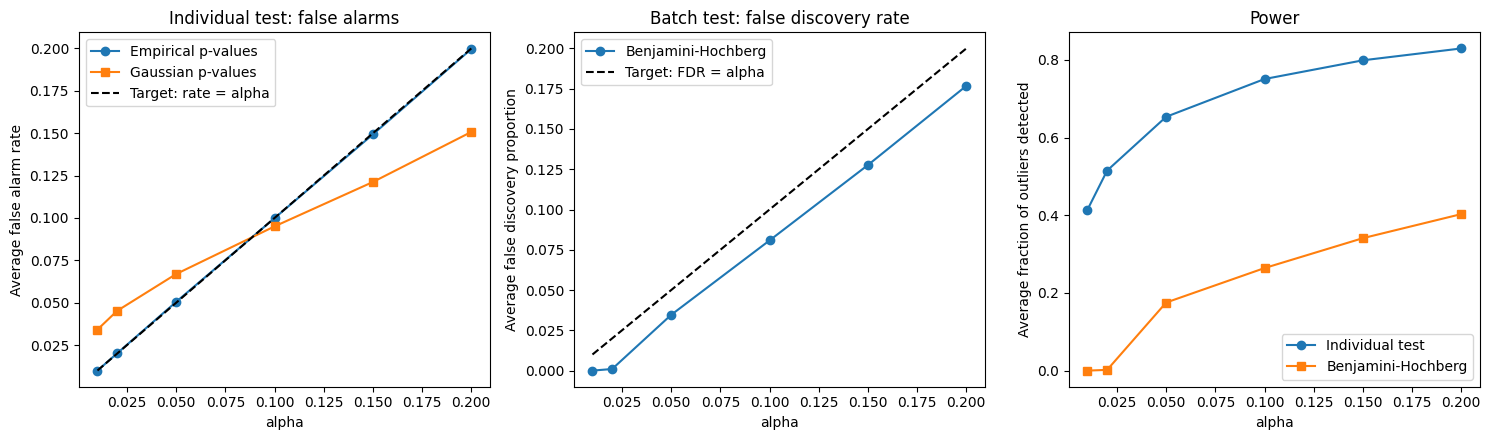

In [12]:
alphas_test = np.array([0.01, 0.02, 0.05, 0.1, 0.15, 0.2])
n_rep = 500
rng = np.random.default_rng(2)

far_emp = np.zeros((n_rep, len(alphas_test)))     # false alarm rate, empirical p-values
far_gauss = np.zeros((n_rep, len(alphas_test)))   # false alarm rate, Gaussian p-values
power_emp = np.zeros((n_rep, len(alphas_test)))   # power of the individual test
fdp_bh = np.zeros((n_rep, len(alphas_test)))      # false discovery proportion of BH
power_bh = np.zeros((n_rep, len(alphas_test)))    # power of BH

for r in range(n_rep):
    perm = rng.permutation(len(s_normal))
    calib = s_normal[perm[:1500]]
    test_normal = s_normal[perm[1500:2500]]
    test_outlier = rng.choice(s_outlier, size=100, replace=False)

    test = np.concatenate([test_normal, test_outlier])
    is_outlier = np.concatenate([np.zeros(1000, dtype=bool), np.ones(100, dtype=bool)])

    p_emp = empirical_pvalues(calib, test)
    p_gauss = gaussian_pvalues(calib, test)

    for k in range(len(alphas_test)):
        a = alphas_test[k]
        far_emp[r, k] = np.mean(p_emp[~is_outlier] <= a)
        far_gauss[r, k] = np.mean(p_gauss[~is_outlier] <= a)
        power_emp[r, k] = np.mean(p_emp[is_outlier] <= a)

        rejected = benjamini_hochberg(p_emp, a)
        fdp_bh[r, k] = np.sum(rejected & ~is_outlier) / max(np.sum(rejected), 1)
        power_bh[r, k] = np.mean(rejected[is_outlier])

# Averages over the repetitions, with the standard error of the empirical false alarm rate
print(f"{'alpha':>6s} | {'false alarms (emp.)':>19s} {'(s.e.)':>8s} {'false alarms (Gauss.)':>21s}"
      f" {'power (indiv.)':>14s} | {'FDR (BH)':>8s} {'power (BH)':>10s}")
for k in range(len(alphas_test)):
    se = far_emp[:, k].std() / np.sqrt(n_rep)
    print(f"{alphas_test[k]:6.2f} | {far_emp[:, k].mean():19.4f} {se:8.4f} {far_gauss[:, k].mean():21.4f}"
          f" {power_emp[:, k].mean():14.3f} | {fdp_bh[:, k].mean():8.4f} {power_bh[:, k].mean():10.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1) Is the false alarm rate below alpha?
axes[0].plot(alphas_test, far_emp.mean(axis=0), marker="o", label="Empirical p-values")
axes[0].plot(alphas_test, far_gauss.mean(axis=0), marker="s", label="Gaussian p-values")
axes[0].plot(alphas_test, alphas_test, "k--", label="Target: rate = alpha")
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("Average false alarm rate")
axes[0].set_title("Individual test: false alarms")
axes[0].legend()

# 2) Is the false discovery rate of BH below alpha?
axes[1].plot(alphas_test, fdp_bh.mean(axis=0), marker="o", label="Benjamini-Hochberg")
axes[1].plot(alphas_test, alphas_test, "k--", label="Target: FDR = alpha")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("Average false discovery proportion")
axes[1].set_title("Batch test: false discovery rate")
axes[1].legend()

# 3) What fraction of the outliers is detected?
axes[2].plot(alphas_test, power_emp.mean(axis=0), marker="o", label="Individual test")
axes[2].plot(alphas_test, power_bh.mean(axis=0), marker="s", label="Benjamini-Hochberg")
axes[2].set_xlabel("alpha")
axes[2].set_ylabel("Average fraction of outliers detected")
axes[2].set_title("Power")
axes[2].legend()

plt.tight_layout()
plt.savefig("figures/guarantees.png", dpi=150)
plt.show()